# 03 — Baseline Models

Compares the naïve mean baseline, Linear Regression, Random Forest, and
HistGradientBoosting on feature group **C** (the richest allowed group).

Protocol:
- 80/20 hold-out split, fixed seed.
- 5-fold cross-validation **on the training partition only**.
- A modest hyperparameter search (3-fold, training only) for the two tree models.
- The test partition is used once, after configurations are fixed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sm_project import config, data, features, modeling, viz

config.ensure_output_dirs()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
print("Project root:", ROOT)
print("Fixed seed:", config.SEED)

Project root: /Users/dhanudriya/Lecturer/ML-project-1
Fixed seed: 42


In [2]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error

df = data.load_data()
analysis = data.eligible_sample(df)
train_idx, test_idx = features.make_split(analysis)
train_df = analysis.iloc[train_idx]
test_df = analysis.iloc[test_idx]
print("Analysis sample:", len(analysis))
print("Training rows:", len(train_df), "| Held-out rows:", len(test_df))
print("Split seed:", config.SEED)

group_name = "C"
feature_list = features.get_feature_group(group_name)
print("Feature group", group_name, "with", len(feature_list), "input features:")
print(feature_list)

Analysis sample: 4415
Training rows: 3532 | Held-out rows: 883
Split seed: 42
Feature group C with 13 input features:
['Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Late_Night_Usage', 'Social_Comparison_Frequency', 'Primary_Platform', 'Device_Type', 'Age', 'Gender', 'Academic_Level', 'Sleep_Duration_Hours', 'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index']


## 1. Modest training-only tuning for the tree models

In [3]:
base_models = modeling.default_models()
param_grids = {
    "Random Forest": {
        "model__n_estimators": [300, 600],
        "model__min_samples_leaf": [1, 2, 4],
    },
    "Hist Gradient Boosting": {
        "model__learning_rate": [0.03, 0.05, 0.10],
        "model__max_leaf_nodes": [15, 31],
    },
}
tuned_estimators = {}
tuning_rows = []
for model_name, grid in param_grids.items():
    pipeline = features.build_pipeline(base_models[model_name], feature_list, scale_numeric=False)
    search = GridSearchCV(
        pipeline, grid, cv=3, scoring="neg_mean_absolute_error", n_jobs=-1
    )
    search.fit(train_df[feature_list], train_df[config.TARGET])
    tuned_estimators[model_name] = search.best_estimator_.named_steps["model"]
    tuning_rows.append(
        {
            "model": model_name,
            "best_cv_mae": -search.best_score_,
            "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
        }
    )
    print(model_name, "best training CV MAE:", round(-search.best_score_, 4), search.best_params_)

tuning_table = pd.DataFrame(tuning_rows)
display(tuning_table)
tuning_table.to_csv(config.TABLES_DIR / "03_tuning_results.csv", index=False)
modeling.save_json(
    {row["model"]: row["best_params"] for row in tuning_rows},
    config.TABLES_DIR / "03_tuned_params.json",
)

Random Forest best training CV MAE: 0.2191 {'model__min_samples_leaf': 4, 'model__n_estimators': 600}


Hist Gradient Boosting best training CV MAE: 0.2203 {'model__learning_rate': 0.03, 'model__max_leaf_nodes': 15}


,model,best_cv_mae,best_params
0,Random Forest,0.219100,"{'min_samples_leaf': 4, 'n_estimators': 600}"
1,Hist Gradient Boosting,0.220306,"{'learning_rate': 0.03, 'max_leaf_nodes': 15}"


## 2. Cross-validation on the training partition

mae            rmse              r2        
                          mean     std    mean     std    mean     std
model                                                                 
Dummy (mean)            0.3090  0.0037  0.3886  0.0067 -0.0045  0.0063
Hist Gradient Boosting  0.2214  0.0036  0.2725  0.0031  0.5056  0.0194
Linear Regression       0.2163  0.0035  0.2665  0.0028  0.5269  0.0204
Random Forest           0.2192  0.0044  0.2697  0.0024  0.5159  0.0193

,model,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_rmse_std,cv_r2_mean,cv_r2_std
0,Dummy (mean),0.3090,0.0037,0.3886,0.0067,-0.0045,0.0063
1,Hist Gradient Boosting,0.2214,0.0036,0.2725,0.0031,0.5056,0.0194
2,Linear Regression,0.2163,0.0035,0.2665,0.0028,0.5269,0.0204
3,Random Forest,0.2192,0.0044,0.2697,0.0024,0.5159,0.0193


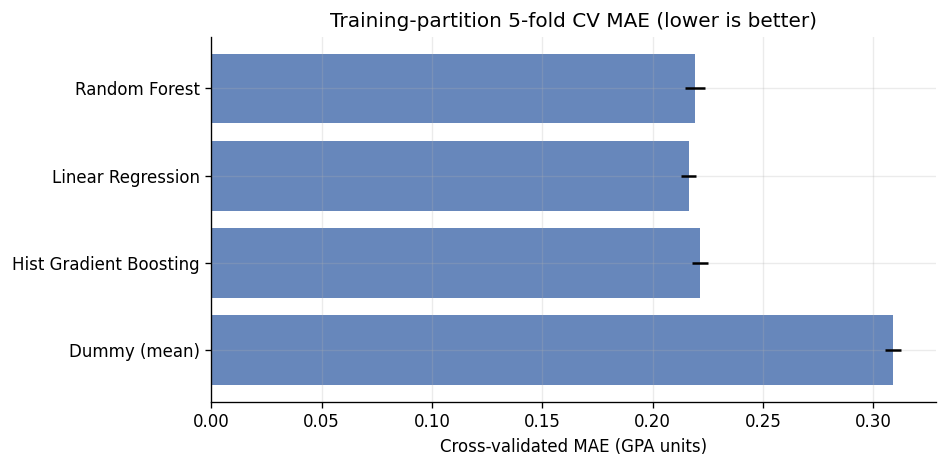

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/03_cv_mae_by_model.png')

In [4]:
models = modeling.default_models()
models["Random Forest"] = tuned_estimators["Random Forest"]
models["Hist Gradient Boosting"] = tuned_estimators["Hist Gradient Boosting"]

cv = modeling.make_cv()
fold_frames = []
for model_name, estimator in models.items():
    folds = modeling.evaluate_cv(
        train_df, feature_list, model_name, estimator, cv,
        scale_numeric=modeling.needs_scaling(model_name),
    )
    fold_frames.append(folds)
fold_results = pd.concat(fold_frames, ignore_index=True)
display(fold_results.groupby("model")[["mae", "rmse", "r2"]].agg(["mean", "std"]).round(4))
fold_results.to_csv(config.TABLES_DIR / "03_cv_fold_results.csv", index=False)

cv_summary = (
    fold_results.groupby("model")
    .agg(
        cv_mae_mean=("mae", "mean"), cv_mae_std=("mae", "std"),
        cv_rmse_mean=("rmse", "mean"), cv_rmse_std=("rmse", "std"),
        cv_r2_mean=("r2", "mean"), cv_r2_std=("r2", "std"),
    )
    .reset_index()
)
display(cv_summary.round(4))
cv_summary.to_csv(config.TABLES_DIR / "03_cv_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(cv_summary["model"], cv_summary["cv_mae_mean"],
        xerr=cv_summary["cv_mae_std"], color="#4C72B0", alpha=0.85)
ax.set_xlabel("Cross-validated MAE (GPA units)")
ax.set_title("Training-partition 5-fold CV MAE (lower is better)")
viz.finish_figure(fig, "03_cv_mae_by_model.png")

## 3. Final held-out evaluation

In [5]:
test_rows = []
prediction_frames = []
for model_name, estimator in models.items():
    metrics, predictions, fitted = modeling.fit_and_test(
        train_df, test_df, feature_list, model_name, estimator,
        scale_numeric=modeling.needs_scaling(model_name),
    )
    test_rows.append(metrics)
    prediction_frames.append(
        pd.DataFrame(
            {
                "row_id": np.arange(len(test_df)),
                "model": model_name,
                "y_true": test_df[config.TARGET].values,
                "y_pred": predictions,
            }
        )
    )

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))
test_results.to_csv(config.TABLES_DIR / "03_test_results.csv", index=False)
all_predictions = pd.concat(prediction_frames, ignore_index=True)
all_predictions.to_csv(config.TABLES_DIR / "03_test_predictions.csv", index=False)

selected = cv_summary.sort_values("cv_mae_mean").iloc[0]["model"]
print("Model selected by training CV MAE:", selected)
modeling.save_json(
    {"selected_model": selected,
     "selection_rule": "lowest mean 5-fold CV MAE on the training partition"},
    config.TABLES_DIR / "03_selected_model.json",
)

,mae,rmse,r2,n_train,n_test,n_features_input,model
0,0.3318,0.4094,-0.0012,3532,883,13,Dummy (mean)
1,0.2179,0.2692,0.5671,3532,883,13,Linear Regression
2,0.2225,0.2746,0.5497,3532,883,13,Random Forest
3,0.2236,0.2756,0.5463,3532,883,13,Hist Gradient Boosting


Model selected by training CV MAE: Linear Regression


## 4. Predicted vs observed for the selected model

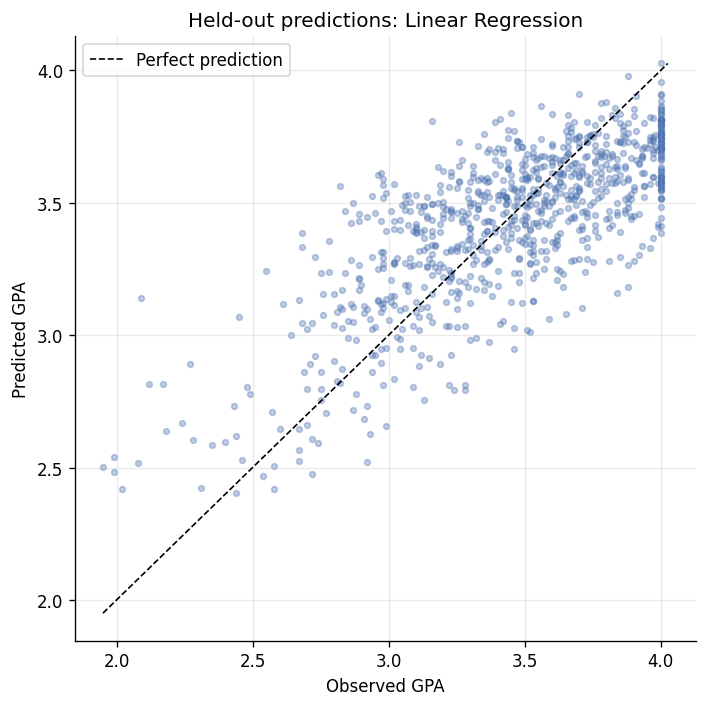

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/03_predicted_vs_observed.png')

In [6]:
sel = all_predictions[all_predictions["model"] == selected]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(sel["y_true"], sel["y_pred"], s=12, alpha=0.35, color="#4C72B0")
lims = [min(sel["y_true"].min(), sel["y_pred"].min()), max(sel["y_true"].max(), sel["y_pred"].max())]
ax.plot(lims, lims, "--", color="black", linewidth=1, label="Perfect prediction")
ax.set_xlabel("Observed GPA")
ax.set_ylabel("Predicted GPA")
ax.set_title(f"Held-out predictions: {selected}")
ax.legend()
viz.finish_figure(fig, "03_predicted_vs_observed.png")

## 5. Summary

In [7]:
best_test = test_results.sort_values("mae").iloc[0]
dummy_row = test_results[test_results["model"] == "Dummy (mean)"].iloc[0]
report_lines = [
    "# Baseline Model Summary",
    "",
    f"- Feature group C ({len(feature_list)} input features); training n={len(train_df):,}, test n={len(test_df):,}.",
    f"- Selected by training CV MAE: **{selected}** (CV MAE {cv_summary.sort_values('cv_mae_mean').iloc[0]['cv_mae_mean']:.4f}).",
    f"- Held-out best MAE: {best_test['mae']:.4f} ({best_test['model']}); "
    f"RMSE {best_test['rmse']:.4f}; R2 {best_test['r2']:.4f}.",
    f"- Naive mean baseline held-out MAE: {dummy_row['mae']:.4f}; RMSE {dummy_row['rmse']:.4f}; R2 {dummy_row['r2']:.4f}.",
    "",
    "The test partition was evaluated once with configurations fixed from training-only CV. "
    "Differences should be read against the fold-to-fold CV standard deviations reported above, "
    "not as evidence of a uniquely superior model.",
]
summary_text = "\n".join(report_lines)
(config.REPORTS_DIR / "03_baseline_models.md").write_text(summary_text, encoding="utf-8")
display(Markdown(summary_text))

# Baseline Model Summary

- Feature group C (13 input features); training n=3,532, test n=883.
- Selected by training CV MAE: **Linear Regression** (CV MAE 0.2163).
- Held-out best MAE: 0.2179 (Linear Regression); RMSE 0.2692; R2 0.5671.
- Naive mean baseline held-out MAE: 0.3318; RMSE 0.4094; R2 -0.0012.

The test partition was evaluated once with configurations fixed from training-only CV. Differences should be read against the fold-to-fold CV standard deviations reported above, not as evidence of a uniquely superior model.